# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Student Depression Dataset](https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

/kaggle/input/datasets/mkhoirulmustaqim/student-depression-detection-dataset/Student Depression Detection Dataset/Student_Depression_Dataset.csv
/kaggle/input/datasets/mkhoirulmustaqim/student-depression-detection-dataset/Student Depression Detection Dataset/Student_Depression_Dataset.xlsx


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('Student_Depression_Dataset.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


## last Five row

In [4]:
df.tail()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


## Shape of our dataset

In [5]:
df.shape

(4464, 13)

## List out all columns

In [6]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Gender                  object
Age                      int64
Family_background       object
Relationship_status     object
Marital_status          object
Living_style            object
Current_semester         int64
CGPA                   float64
friend_circle           object
Health_condition        object
Cost_without_study       int64
Home_division           object
Depression              object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


## Check Null Value

In [9]:
df.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

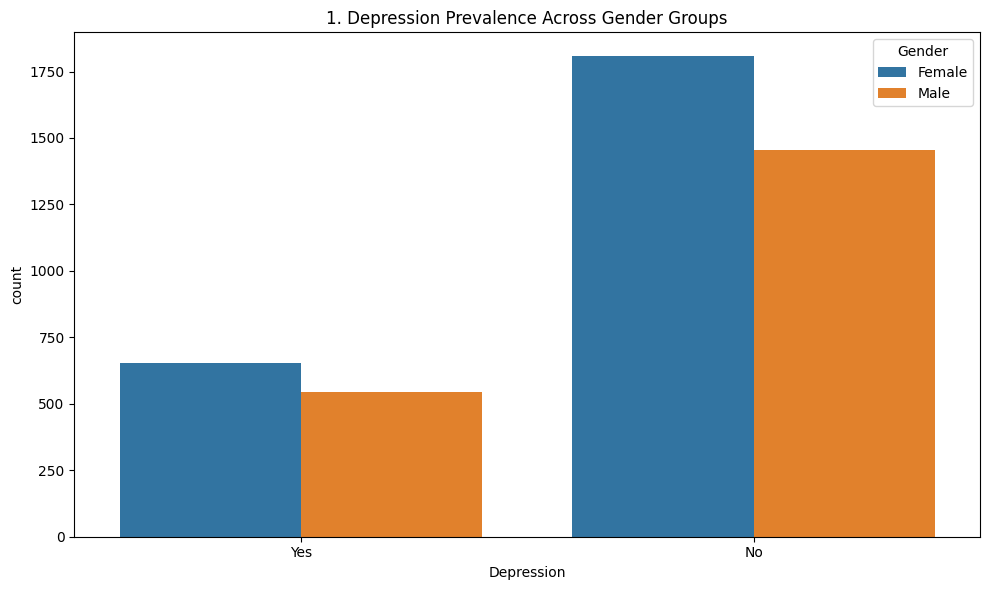

In [13]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Depression', hue='Gender')
plt.title(f'{plot_no}. Depression Prevalence Across Gender Groups')
show_fig()
plot_no += 1

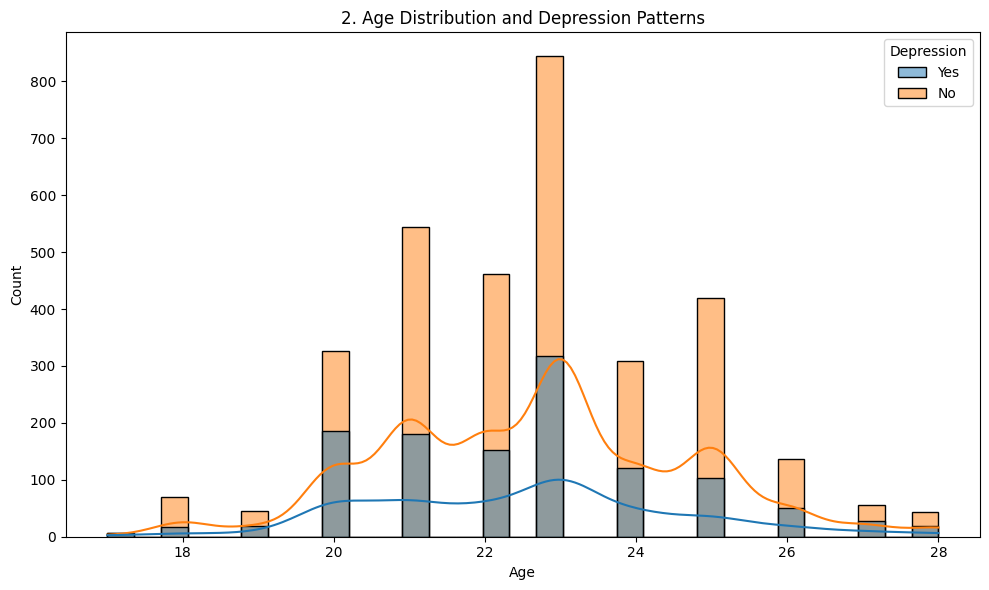

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Age', hue='Depression', multiple='layer', kde=True)
plt.title(f'{plot_no}. Age Distribution and Depression Patterns')
show_fig()
plot_no += 1

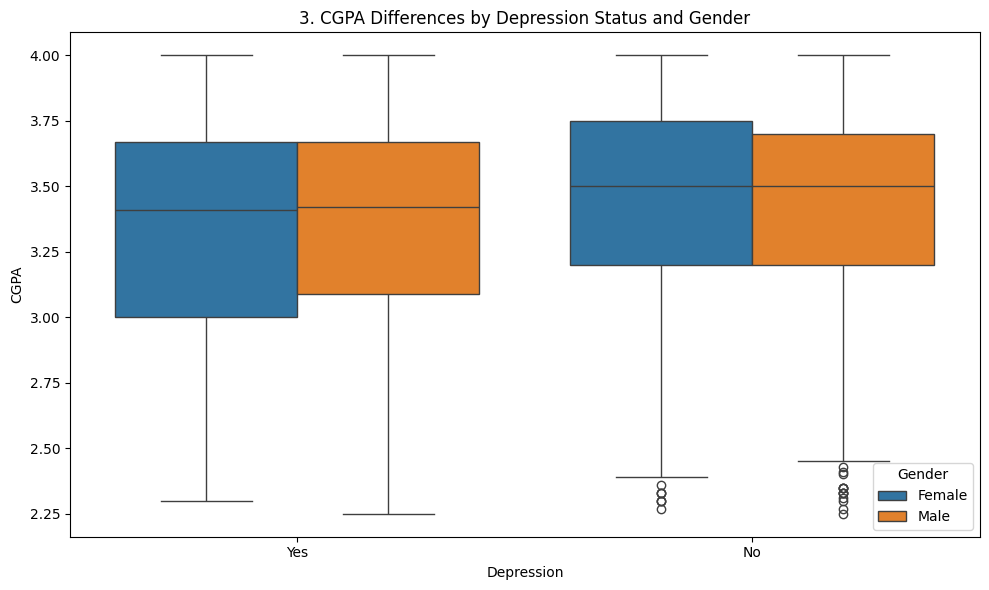

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Depression', y='CGPA', hue='Gender')
plt.title(f'{plot_no}. CGPA Differences by Depression Status and Gender')
show_fig()
plot_no += 1

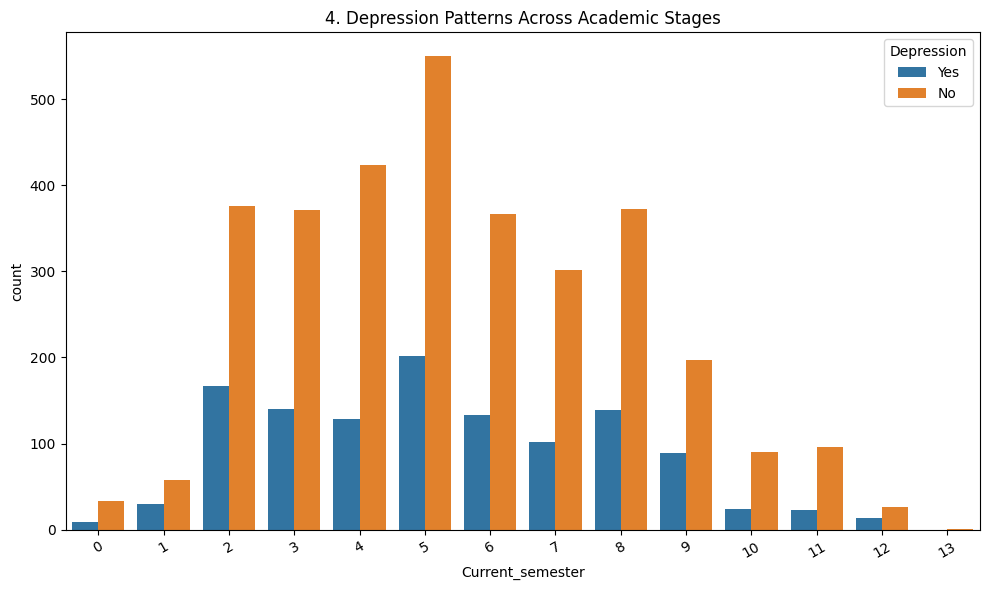

In [16]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Current_semester', hue='Depression')
plt.title(f'{plot_no}. Depression Patterns Across Academic Stages')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

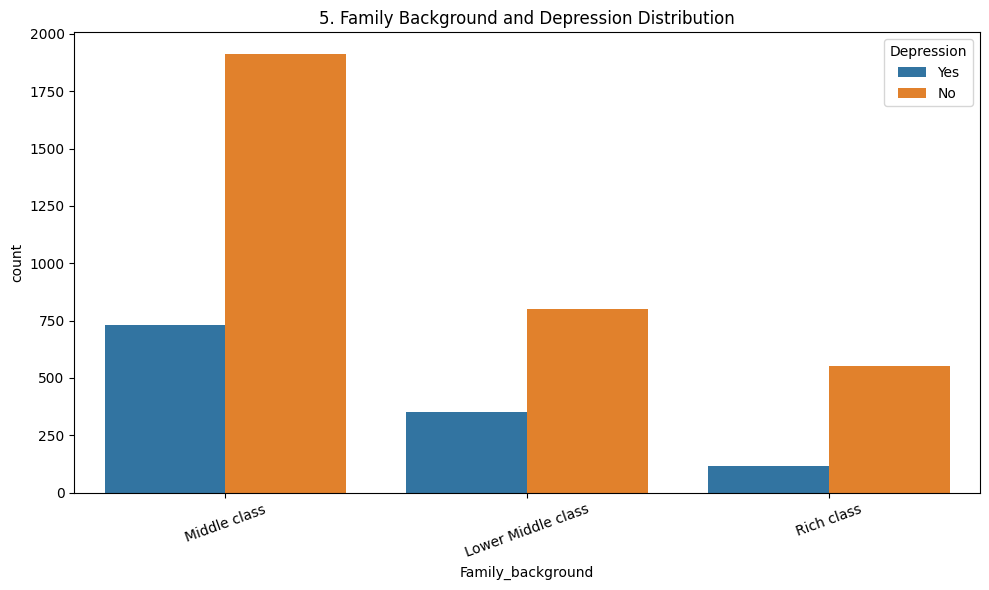

In [17]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Family_background', hue='Depression')
plt.title(f'{plot_no}. Family Background and Depression Distribution')
plt.xticks(rotation=20)
show_fig()
plot_no += 1

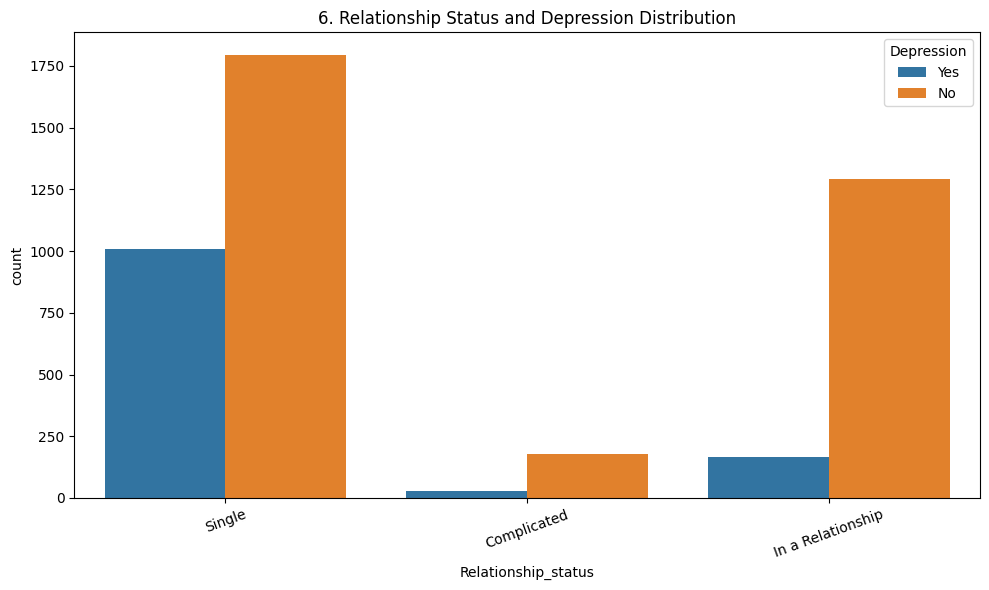

In [18]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Relationship_status', hue='Depression')
plt.title(f'{plot_no}. Relationship Status and Depression Distribution')
plt.xticks(rotation=20)
show_fig()
plot_no += 1

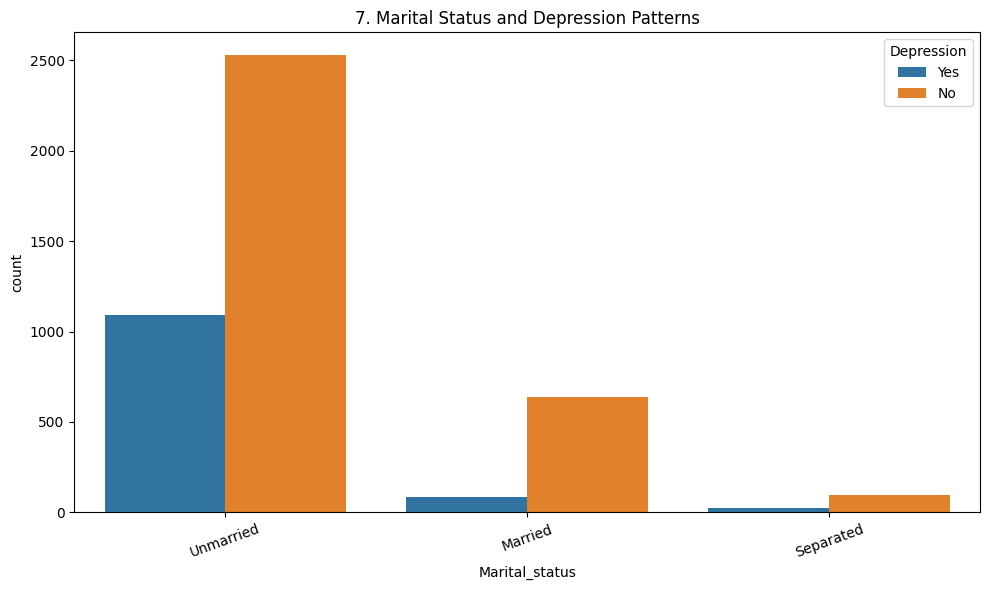

In [19]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Marital_status', hue='Depression')
plt.title(f'{plot_no}. Marital Status and Depression Patterns')
plt.xticks(rotation=20)
show_fig()
plot_no += 1

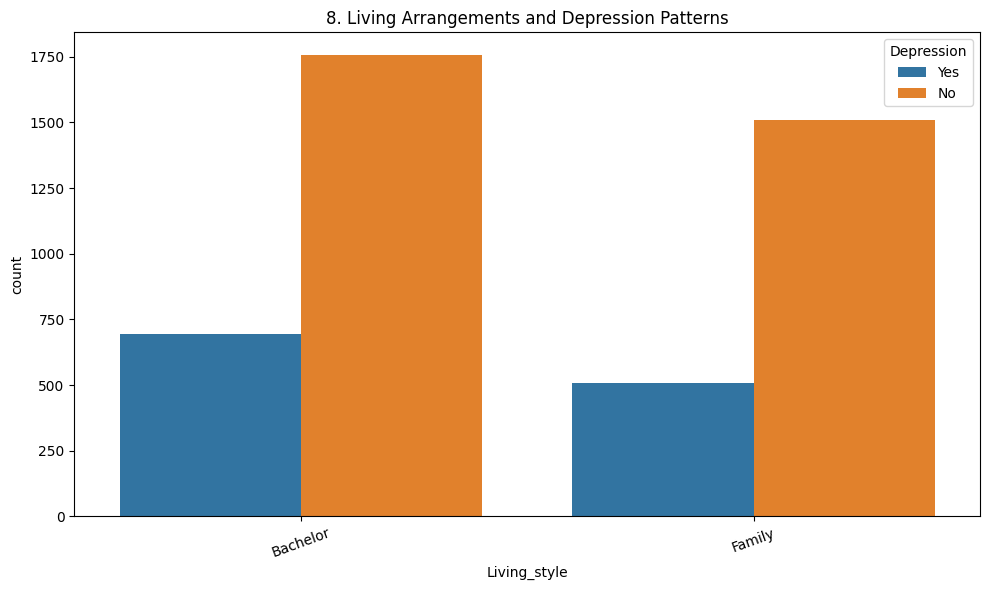

In [20]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Living_style', hue='Depression')
plt.title(f'{plot_no}. Living Arrangements and Depression Patterns')
plt.xticks(rotation=20)
show_fig()
plot_no += 1

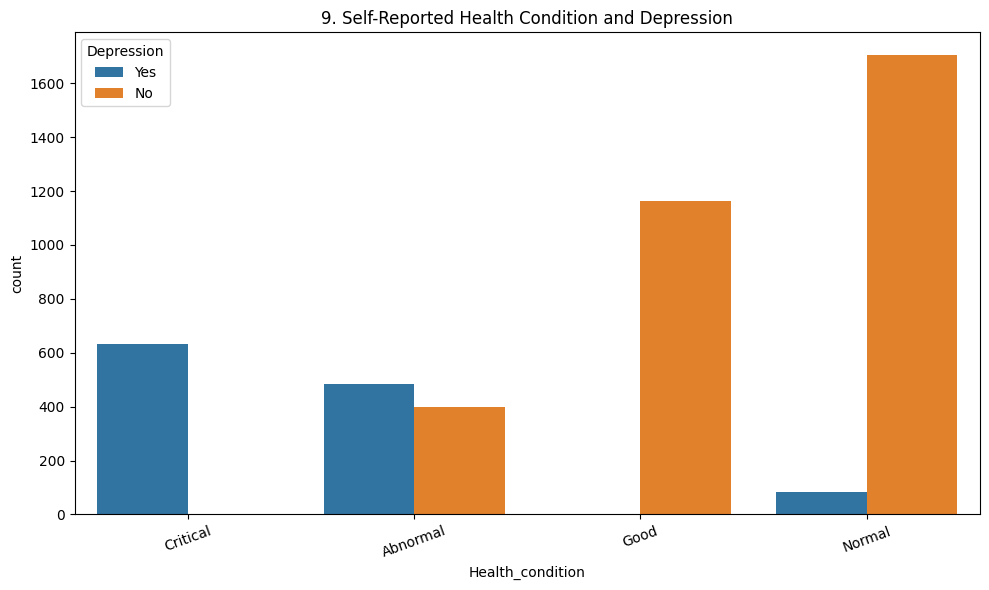

In [21]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Health_condition', hue='Depression')
plt.title(f'{plot_no}. Self-Reported Health Condition and Depression')
plt.xticks(rotation=20)
show_fig()
plot_no += 1

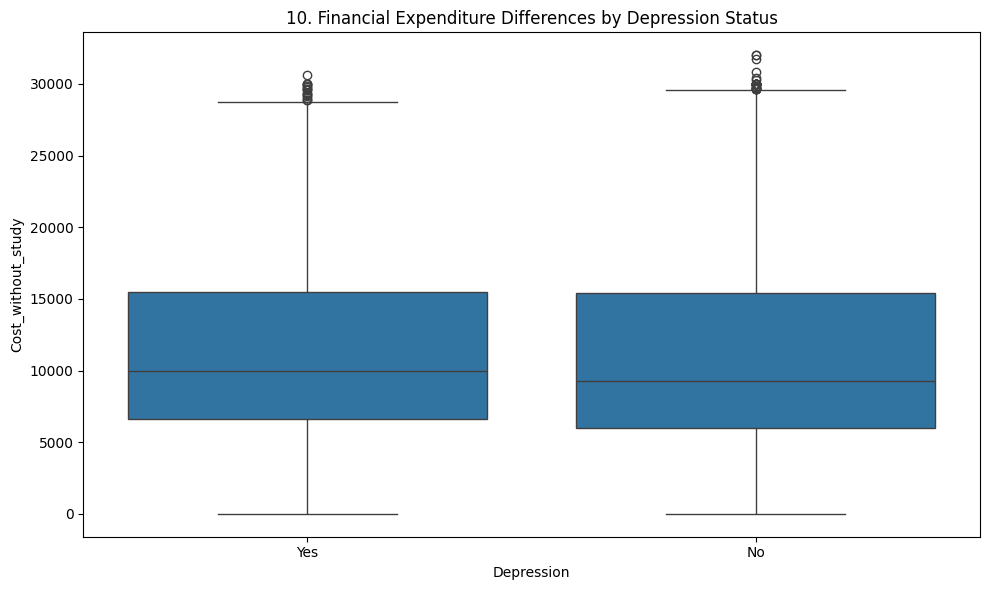

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Depression', y='Cost_without_study')
plt.title(f'{plot_no}. Financial Expenditure Differences by Depression Status')
show_fig()
plot_no += 1

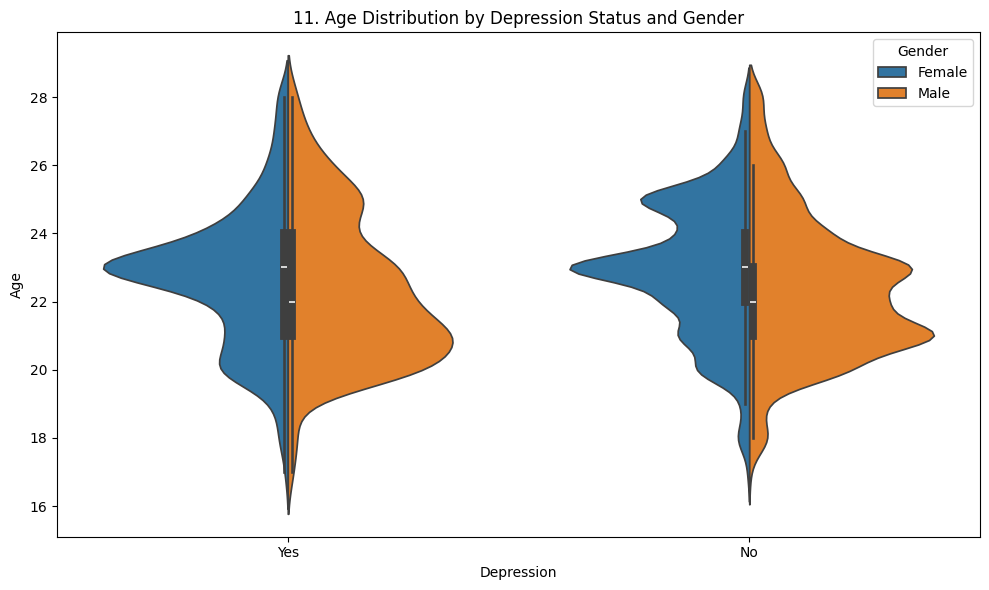

In [23]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='Depression', y='Age', hue='Gender', split=True)
plt.title(f'{plot_no}. Age Distribution by Depression Status and Gender')
show_fig()
plot_no += 1

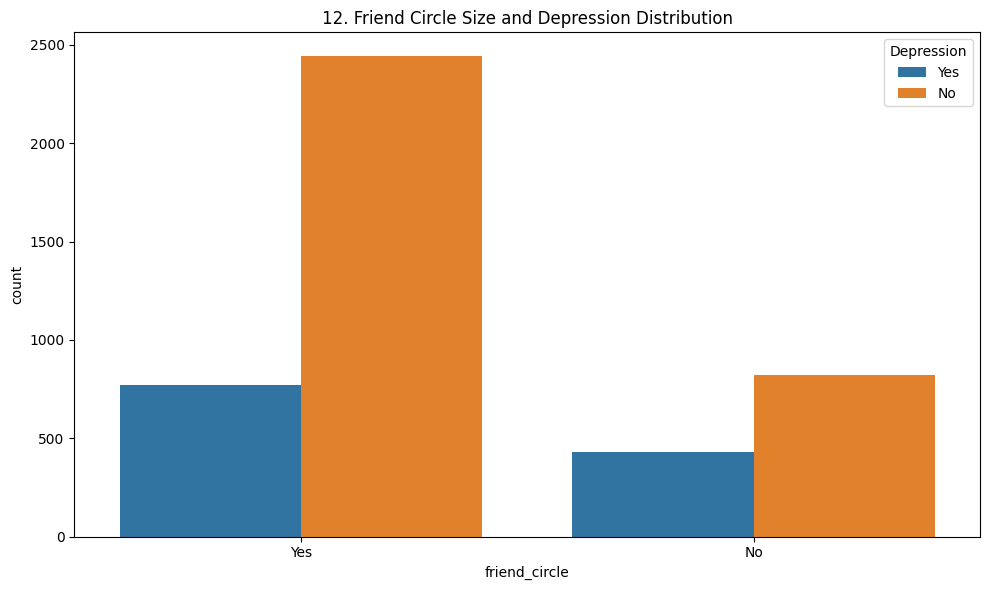

In [24]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='friend_circle', hue='Depression')
plt.title(f'{plot_no}. Friend Circle Size and Depression Distribution')
show_fig()
plot_no += 1

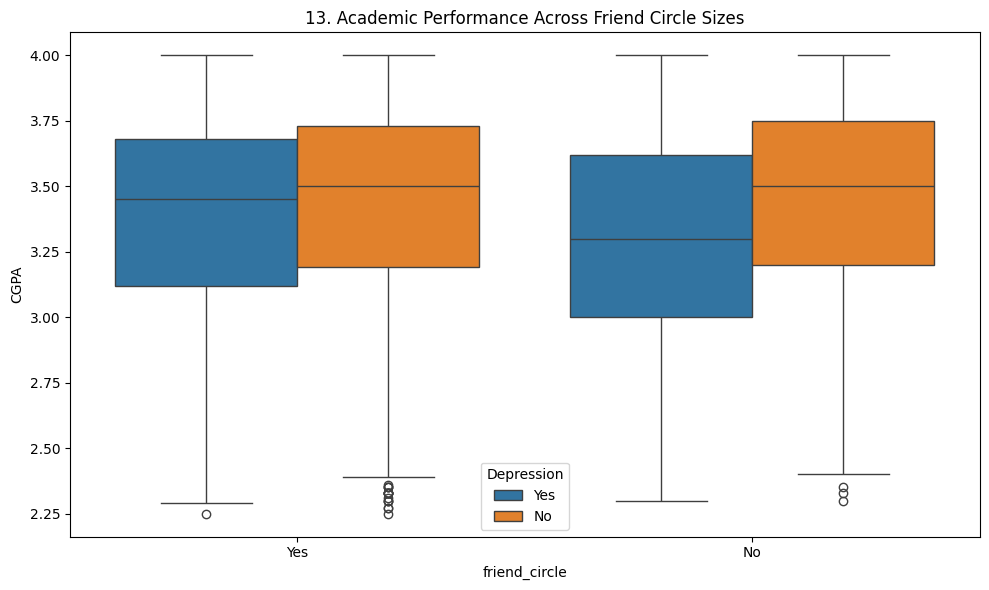

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='friend_circle', y='CGPA', hue='Depression')
plt.title(f'{plot_no}. Academic Performance Across Friend Circle Sizes')
show_fig()
plot_no += 1

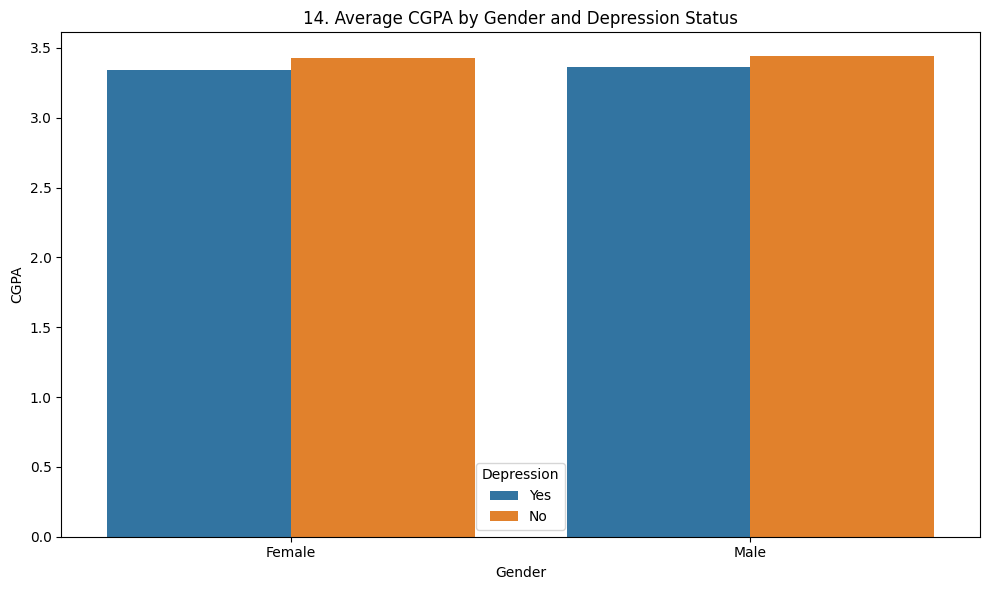

In [26]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Gender', y='CGPA', hue='Depression', errorbar=None)
plt.title(f'{plot_no}. Average CGPA by Gender and Depression Status')
show_fig()
plot_no += 1

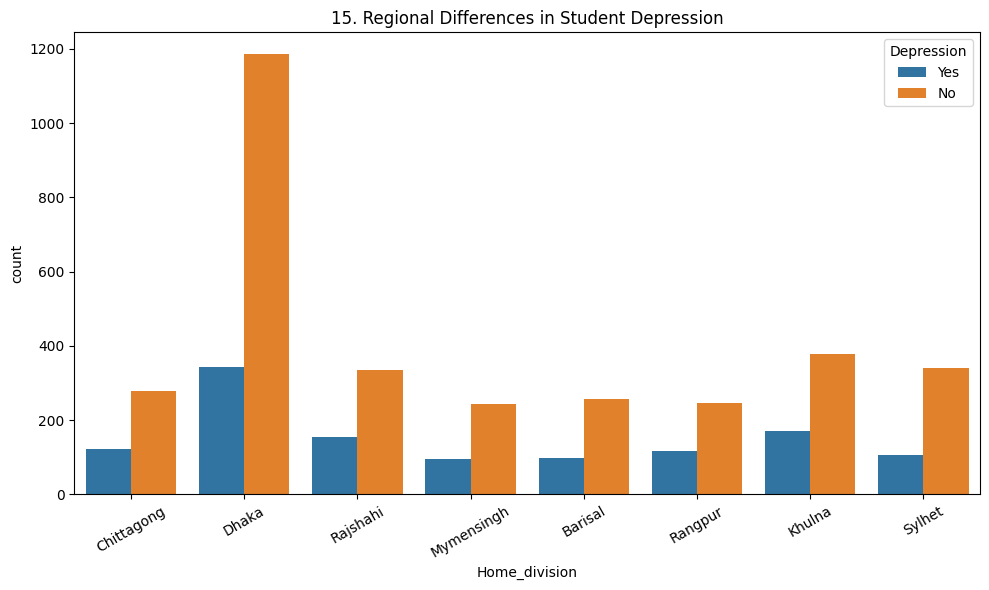

In [27]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Home_division', hue='Depression')
plt.title(f'{plot_no}. Regional Differences in Student Depression')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

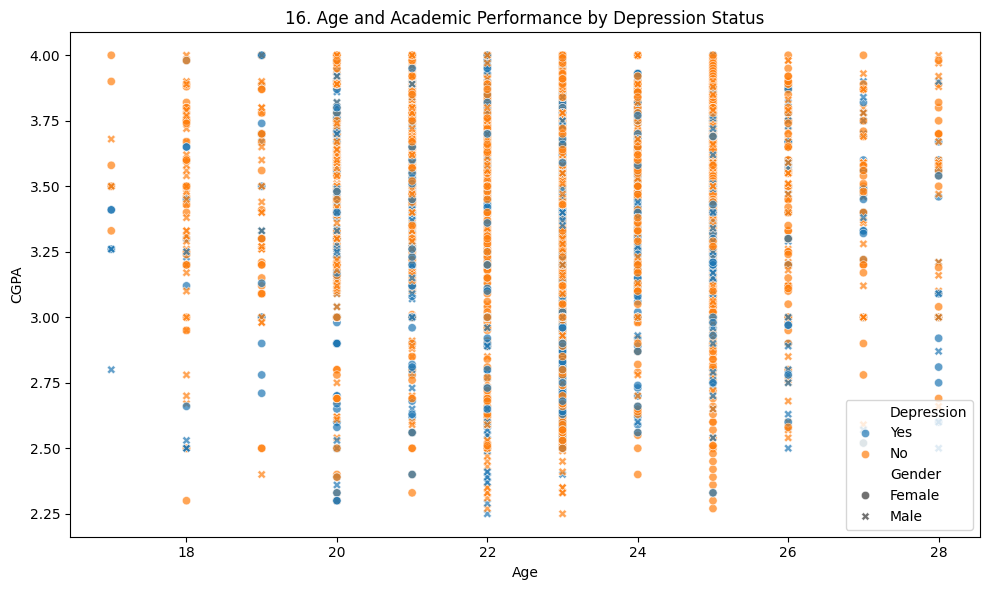

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Age', y='CGPA', hue='Depression', style='Gender', alpha=0.7)
plt.title(f'{plot_no}. Age and Academic Performance by Depression Status')
show_fig()
plot_no += 1

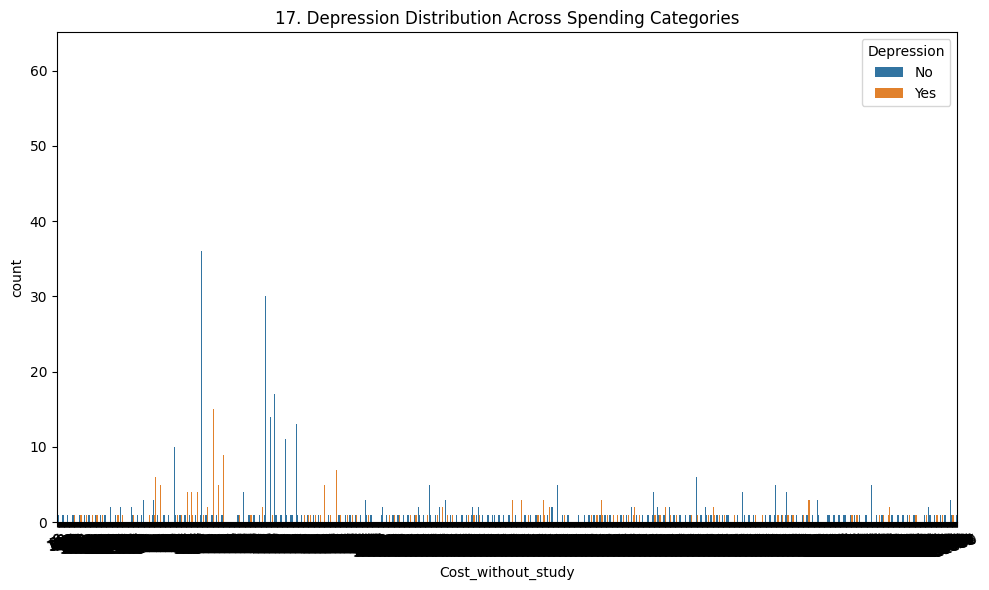

In [29]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Cost_without_study', hue='Depression')
plt.title(f'{plot_no}. Depression Distribution Across Spending Categories')
plt.xticks(rotation=20)
show_fig()
plot_no += 1

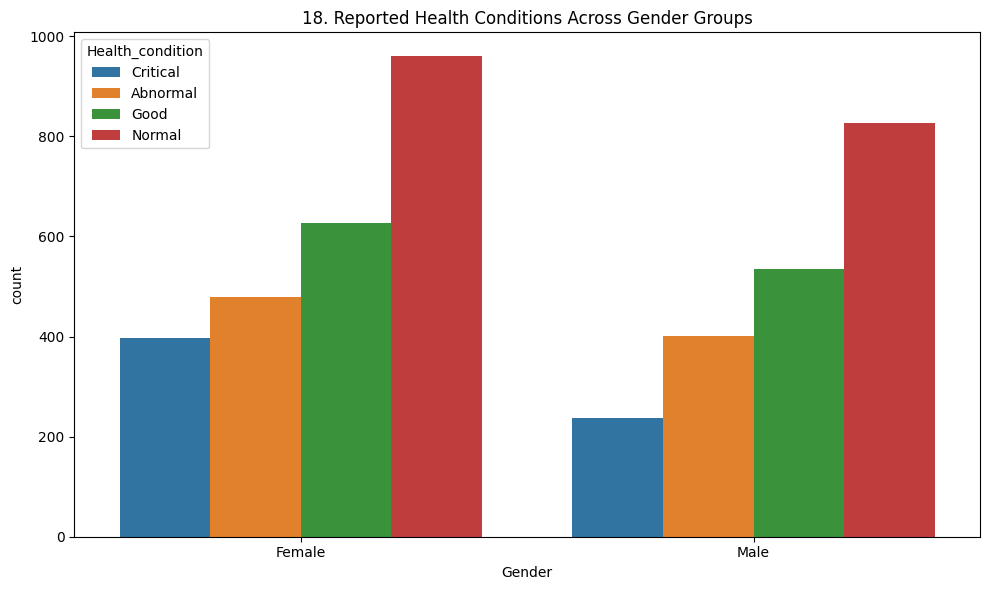

In [30]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Gender', hue='Health_condition')
plt.title(f'{plot_no}. Reported Health Conditions Across Gender Groups')
show_fig()
plot_no += 1

<Figure size 1000x600 with 0 Axes>

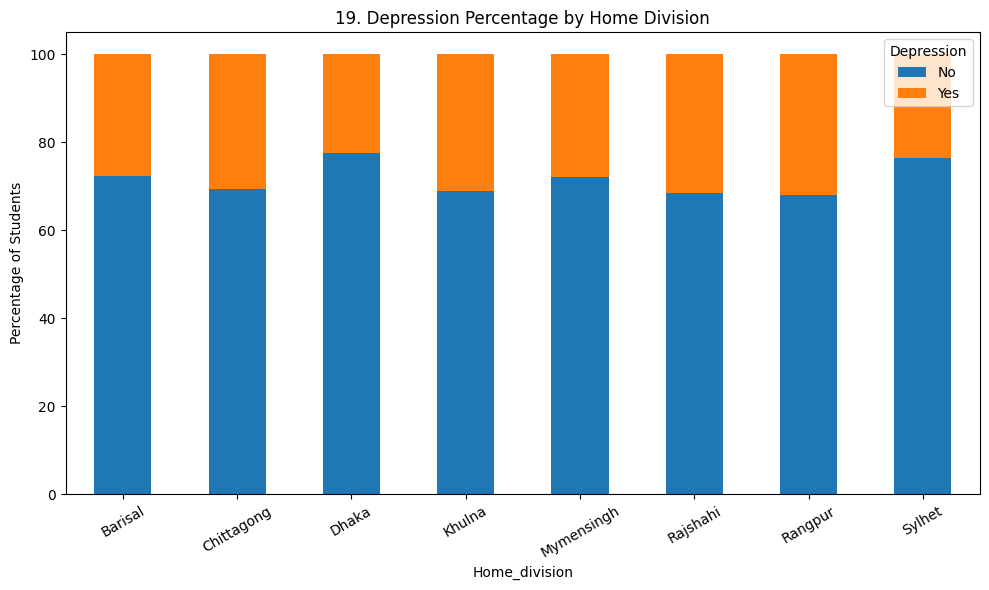

In [31]:
fig = plt.figure(figsize=(10,6))
depression_rate = pd.crosstab(df['Home_division'], df['Depression'], normalize='index') * 100
depression_rate.plot(kind='bar', stacked=True, figsize=(10,6))
plt.title(f'{plot_no}. Depression Percentage by Home Division')
plt.ylabel('Percentage of Students')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

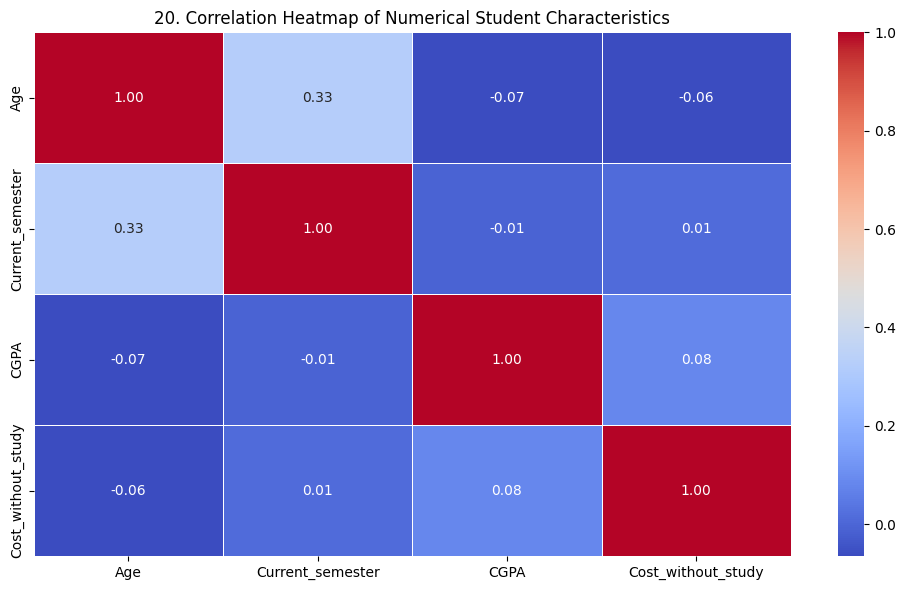

In [32]:
corr = df.select_dtypes(include='number').corr()
fig = plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Numerical Student Characteristics')
show_fig()
plot_no += 1

# Model Training

## Prepare features and target

In [33]:
data = df.dropna(subset=['Depression']).copy()
X = data.drop(columns=['Depression'])
y = data['Depression'].astype(str).str.strip()

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

## Preprocess missing values and scale numerical features

In [35]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

## Encode categorical features

In [36]:
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

## Combine preprocessing steps

In [37]:
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Build the classification model

In [38]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

## Split the dataset into training and testing sets

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Train the model

In [40]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Current_semester',
                                                   'CGPA',
                                                   'Cost_without_study']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender',
                                                   'Family_background',
                                                   'Relationship_status',
                                                   'Marital_status',
                                                   'Living_style',
                                                   'friend_circle',
                                                   'Health_condition',
                                                   'Home_division'])])),
                ('classifier', LogisticRegression(max_iter=2000))])

## Predict test-set outcomes

In [41]:
y_pred = model.predict(X_test)

## Print evaluation metrics

In [42]:
print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 0.9709

Classification Report:

              precision    recall  f1-score   support

          No       0.97      0.99      0.98       653
         Yes       0.96      0.93      0.94       240

    accuracy                           0.97       893
   macro avg       0.97      0.96      0.96       893
weighted avg       0.97      0.97      0.97       893



## Plot the confusion matrix

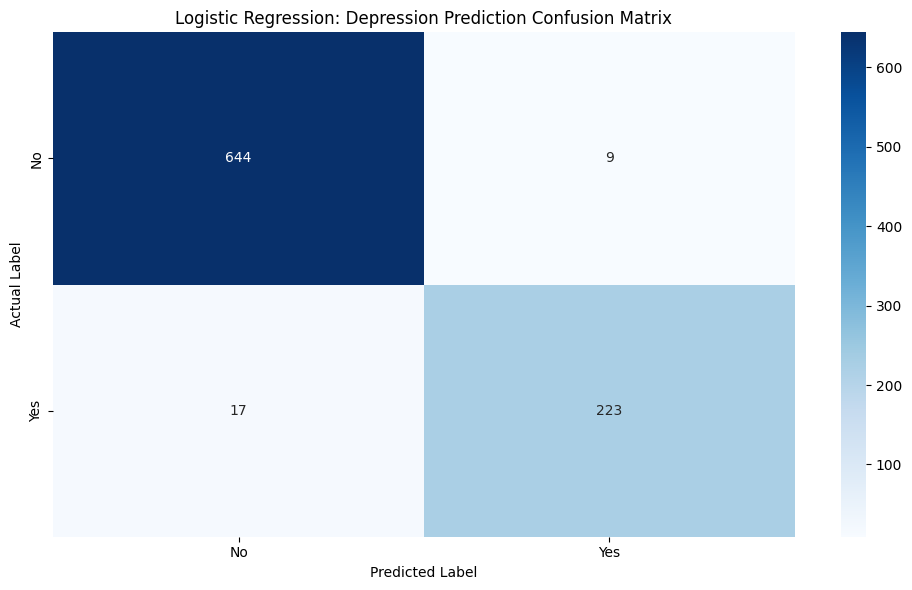

In [43]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
fig = plt.figure(figsize=(10, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.title('Logistic Regression: Depression Prediction Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()